## Stage 1: Load and Prepare Time Series Data

We will use daily stock closing prices to explore trends, stationarity, and differencing. We will use monthly airline passenger data later to understand seasonality and build a SARIMA model.

Time series observations must be kept in chronological order because past observations help us predict future observations.

In [1]:
!pip install yfinance
!pip install matplotlib
!pip install statsmodels
!pip install scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [3]:
# Download daily stock data
stock = yf.download(
  'AAPL',
  start='2019-01-01',
  end='2025-01-01',
  auto_adjust=True,
  progress=False
)

# Keep the closing price series
stock_close = stock['Close']

# Ensure dates run from oldest to newest
stock_close = stock_close.sort_index()

print("Head: \n", stock_close.head())
print("\n\n")
print("Tail: \n", stock_close.tail())
print("\n\n")
print("Index: \n", stock_close.index)

Head: 
 Ticker           AAPL
Date                 
2019-01-02  37.436916
2019-01-03  33.707928
2019-01-04  35.146885
2019-01-07  35.068661
2019-01-08  35.737179



Tail: 
 Ticker            AAPL
Date                  
2024-12-24  256.339752
2024-12-26  257.153809
2024-12-27  253.748535
2024-12-30  250.382950
2024-12-31  248.615768



Index: 
 DatetimeIndex(['2019-01-02', '2019-01-03', '2019-01-04', '2019-01-07',
               '2019-01-08', '2019-01-09', '2019-01-10', '2019-01-11',
               '2019-01-14', '2019-01-15',
               ...
               '2024-12-17', '2024-12-18', '2024-12-19', '2024-12-20',
               '2024-12-23', '2024-12-24', '2024-12-26', '2024-12-27',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[s]', name='Date', length=1510, freq=None)


### Load a Seasonal Time Series

The airline passenger dataset contains monthly passenger counts. Unlike stock prices, it has a repeating yearly pattern and a long-term upward trend.

We will use it to study trend, seasonality, decomposition, and SARIMA.

In [4]:
from statsmodels.datasets import get_rdataset

airline = get_rdataset("AirPassengers").data

airline["Month"] = pd.date_range(
    start="1949-01-01",
    periods=len(airline),
    freq="MS"
)

airline = airline.set_index("Month")
airline = airline["value"].rename("Passengers")

print(airline.head())
print(airline.tail())
print(airline.index)

Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Name: Passengers, dtype: int64
Month
1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Name: Passengers, dtype: int64
DatetimeIndex(['1949-01-01', '1949-02-01', '1949-03-01', '1949-04-01',
               '1949-05-01', '1949-06-01', '1949-07-01', '1949-08-01',
               '1949-09-01', '1949-10-01',
               ...
               '1960-03-01', '1960-04-01', '1960-05-01', '1960-06-01',
               '1960-07-01', '1960-08-01', '1960-09-01', '1960-10-01',
               '1960-11-01', '1960-12-01'],
              dtype='datetime64[us]', name='Month', length=144, freq=None)


### Visual Inspection: Stock Prices vs Airline Passengers

Before modeling, plot the raw time series. Look for long-term trends, repeating patterns, sudden changes, and differences in variability.

Visual inspection helps us form hypotheses, but we will use statistical tests later to investigate stationarity.

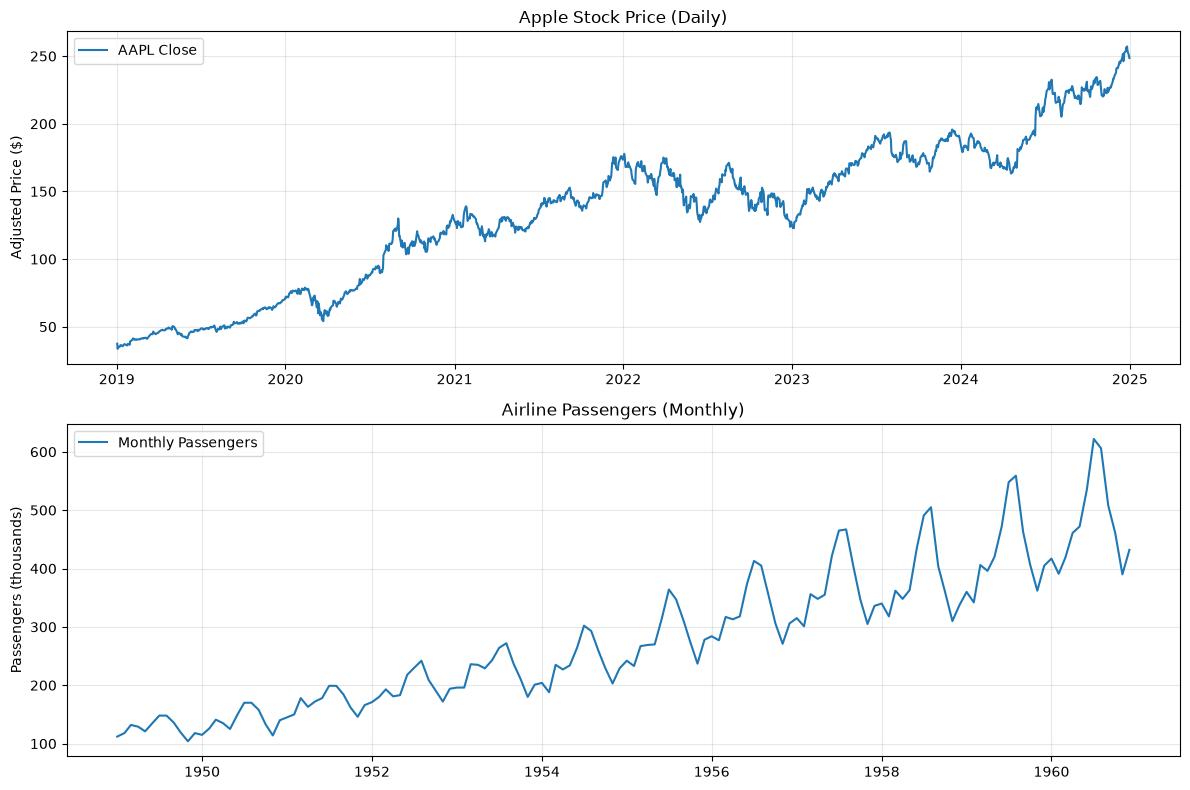

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Stock prices
axes[0].plot(stock_close.index, stock_close.squeeze(), label="AAPL Close")
axes[0].set_title("Apple Stock Price (Daily)")
axes[0].set_ylabel("Adjusted Price ($)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Airline passengers
axes[1].plot(airline.index, airline, label="Monthly Passengers")
axes[1].set_title("Airline Passengers (Monthly)")
axes[1].set_ylabel("Passengers (thousands)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Rolling Mean: Reveal the Underlying Trend

A rolling mean calculates the average across a moving window. For monthly airline data, a 12-month rolling mean smooths one year's worth of observations at a time. For daily stock data, a 30-observation rolling mean smooths roughly six trading weeks.

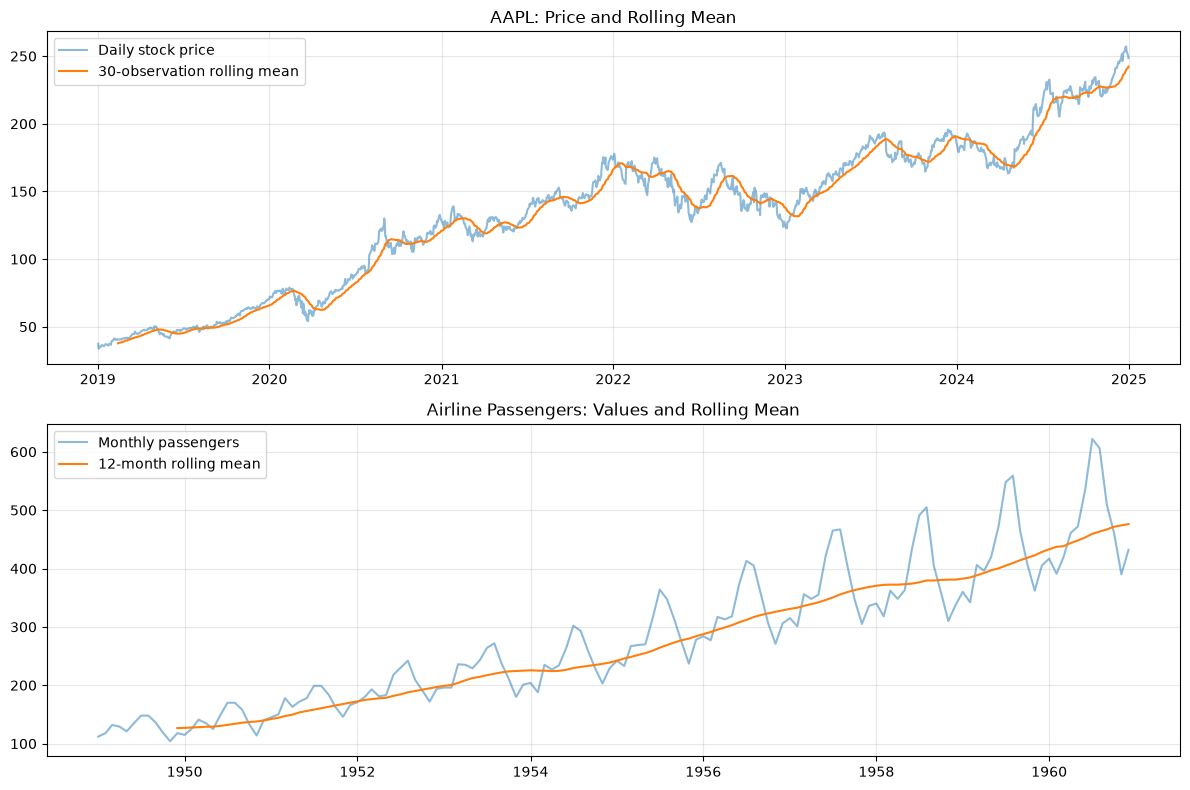

In [6]:
stock_series = stock_close.squeeze()

stock_roll = stock_series.rolling(window=30).mean()
airline_roll = airline.rolling(window=12).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(stock_series, alpha=0.5, label="Daily stock price")
axes[0].plot(stock_roll, label="30-observation rolling mean")
axes[0].set_title("AAPL: Price and Rolling Mean")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(airline, alpha=0.5, label="Monthly passengers")
axes[1].plot(airline_roll, label="12-month rolling mean")
axes[1].set_title("Airline Passengers: Values and Rolling Mean")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## Stage 2: Time-Series Decomposition

A time series can contain three main components:

- **Trend:** long-term upward or downward movement.
- **Seasonality:** a pattern that repeats at a fixed interval.
- **Residual:** what remains after removing the estimated trend and seasonality.

The additive model represents the series as trend + seasonality + residual. The multiplicative model represents it as trend × seasonality × residual, which is useful when seasonal swings grow with the level of the series.

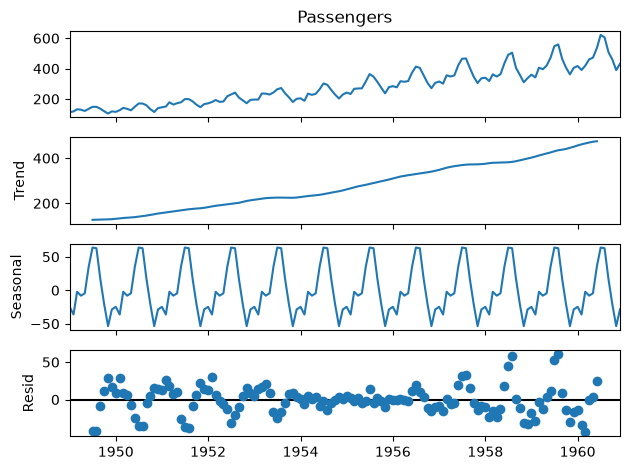

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    airline,
    model="additive",
    period=12
)

decomposition.plot()
plt.tight_layout()
plt.show()

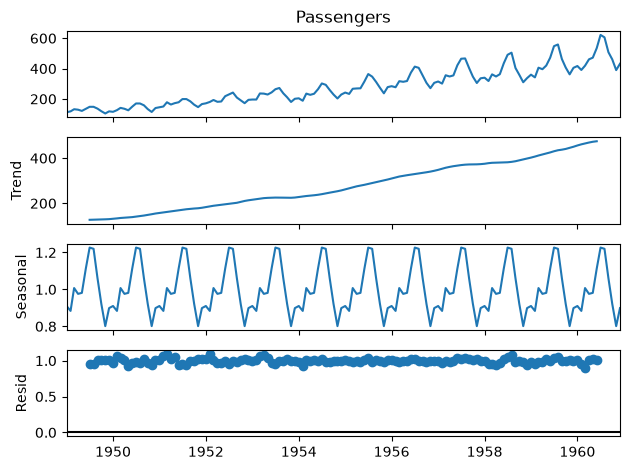

In [8]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    airline,
    model="multiplicative",
    period=12
)

decomposition.plot()
plt.tight_layout()
plt.show()

---

### Check Stationarity Visually

A rolling mean helps us see whether the average level changes over time. A rolling standard deviation helps us see whether variability changes over time.

If these statistics shift substantially, the series may be non-stationary. This is a visual clue, not a definitive test.

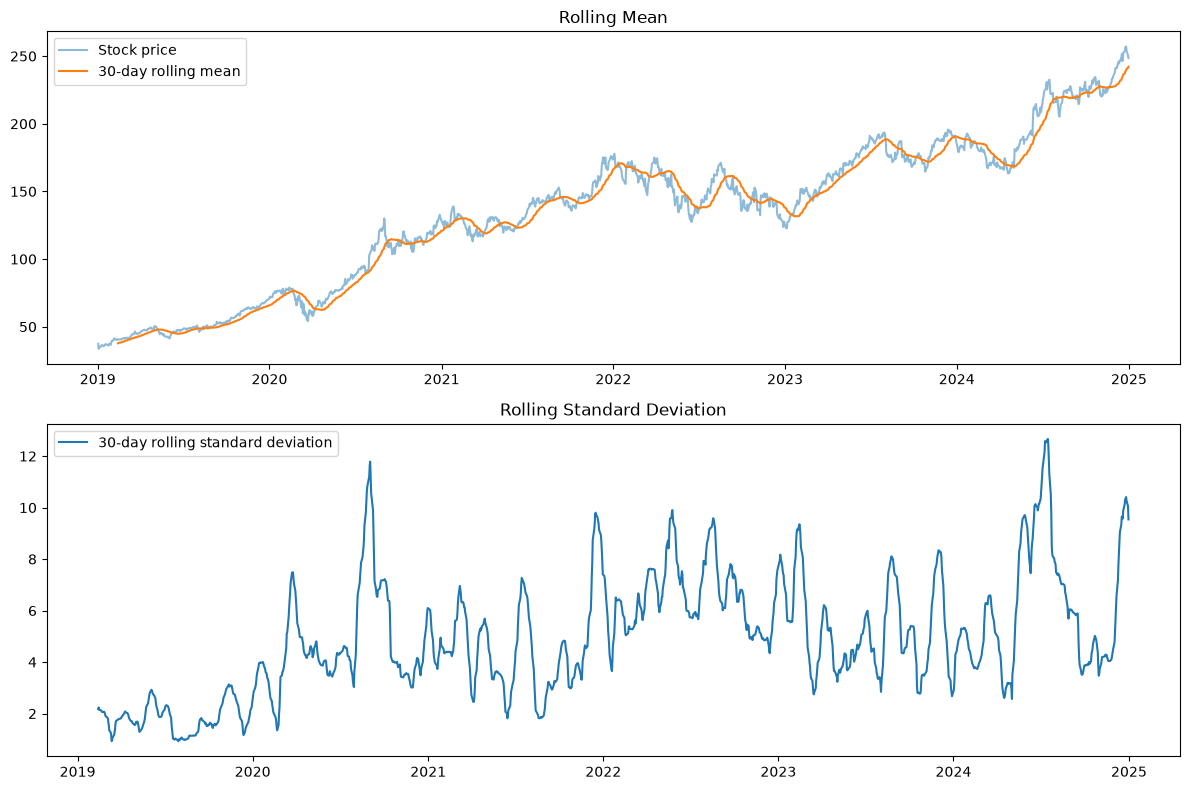

In [9]:
rolling_mean = stock_series.rolling(window=30).mean()
rolling_std = stock_series.rolling(window=30).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(stock_series, label="Stock price", alpha=0.5)
axes[0].plot(rolling_mean, label="30-day rolling mean")
axes[0].set_title("Rolling Mean")
axes[0].legend()

axes[1].plot(rolling_std, label="30-day rolling standard deviation")
axes[1].set_title("Rolling Standard Deviation")
axes[1].legend()

plt.tight_layout()
plt.show()

### Augmented Dickey-Fuller (ADF) Test

The ADF test checks the null hypothesis that the series has a unit root.

- **Null hypothesis (H₀):** the series has a unit root.
- **Alternative hypothesis (H₁):** the series does not have a unit root.

A small p-value (commonly below 0.05) gives evidence to reject the null hypothesis. A large p-value means we fail to reject it; it does not prove the series is non-stationary.

In [10]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(stock_series.dropna())

print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical values:", adf_result[4])

ADF statistic: -0.517119459991652
p-value: 0.8886322312642361
Critical values: {'1%': np.float64(-3.434690926976026), '5%': np.float64(-2.863457245470903), '10%': np.float64(-2.5677907166982643)}


/var/folders/h6/8v7ghg7d5pzgkx9ldll6y32m0000gn/T/ipykernel_33234/721975375.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(stock_series.dropna())


### First-Order Differencing

First-order differencing subtracts each observation from the previous observation. This often removes a changing level or trend and can make a series more stationary. It does not guarantee stationarity.

In [11]:
# Calculate day-to-day price changes
stock_diff = stock_series.diff().dropna()

# Run ADF on the differenced series
adf_diff = adfuller(stock_diff)

print("ADF statistic:", adf_diff[0])
print("p-value:", adf_diff[1])

ADF statistic: -39.45078980103741
p-value: 0.0


/var/folders/h6/8v7ghg7d5pzgkx9ldll6y32m0000gn/T/ipykernel_33234/3497139404.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(stock_diff)


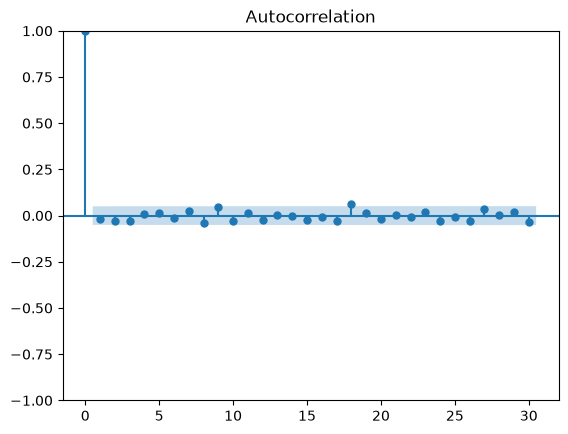

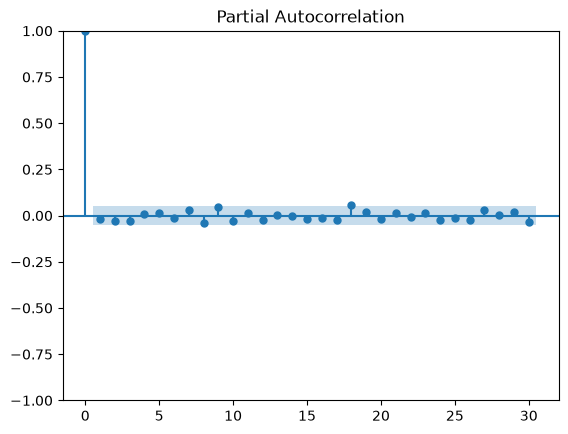

In [12]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

plot_acf(stock_diff, lags=30)
plt.show()

plot_pacf(stock_diff, lags=30, method="ywm")
plt.show()

In [13]:
from statsmodels.tsa.stattools import acf, pacf

acf_values = acf(stock_diff, nlags=30)
pacf_values = pacf(stock_diff, nlags=30, method="ywm")

print("ACF:", acf_values.round(3))
print("PACF:", pacf_values.round(3))

ACF: [ 1.    -0.016 -0.027 -0.027  0.01   0.014 -0.011  0.027 -0.041  0.048
 -0.032  0.014 -0.024  0.005 -0.002 -0.024 -0.006 -0.03   0.063  0.015
 -0.019  0.005 -0.006  0.017 -0.028 -0.006 -0.028  0.036  0.004  0.018
 -0.033]
PACF: [ 1.    -0.016 -0.028 -0.028  0.008  0.013 -0.011  0.028 -0.041  0.047
 -0.032  0.014 -0.023  0.004 -0.005 -0.021 -0.012 -0.026  0.056  0.02
 -0.02   0.013 -0.008  0.015 -0.025 -0.011 -0.024  0.029  0.003  0.021
 -0.033]


In [14]:
from statsmodels.tsa.arima.model import ARIMA

split = int(len(stock_series) * 0.8)
train = stock_series.iloc[:split]
test = stock_series.iloc[split:]

model = ARIMA(train, order=(1, 1, 1))
fitted_model = model.fit()

print(fitted_model.summary())

                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                 1208
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -2746.138
Date:                Tue, 20 Oct 2026   AIC                           5498.276
Time:                        12:33:14   BIC                           5513.564
Sample:                             0   HQIC                          5504.033
                               - 1208                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4620      0.354      1.304      0.192      -0.233       1.157
ma.L1         -0.5059      0.348     -1.455      0.146      -1.187       0.175
sigma2         5.5426      0.152     36.395      0.0

/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [15]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use observation numbers instead of irregular dates
prices = pd.Series(stock_series.to_numpy(), dtype="float64")

split = int(len(prices) * 0.8)
train = prices.iloc[:split]
test = prices.iloc[split:]

# Refit the model using the integer index
model = ARIMA(train, order=(1, 1, 1))
fitted_model = model.fit()

# Forecast the test observations
forecast = np.asarray(fitted_model.forecast(steps=len(test)))

# Naive baseline: repeat the last training price
naive = np.repeat(train.iloc[-1], len(test))

print(f"ARIMA MAE:  {mean_absolute_error(test, forecast):.3f}")
print(f"ARIMA RMSE: {np.sqrt(mean_squared_error(test, forecast)):.3f}")
print(f"Naive MAE:  {mean_absolute_error(test, naive):.3f}")
print(f"Naive RMSE: {np.sqrt(mean_squared_error(test, naive)):.3f}")

ARIMA MAE:  29.773
ARIMA RMSE: 37.514
Naive MAE:  29.895
Naive RMSE: 37.650


count    1208.000000
mean        0.153784
std         2.584604
min       -10.158710
25%        -0.897667
50%         0.149410
75%         1.281364
max        37.436916
dtype: float64


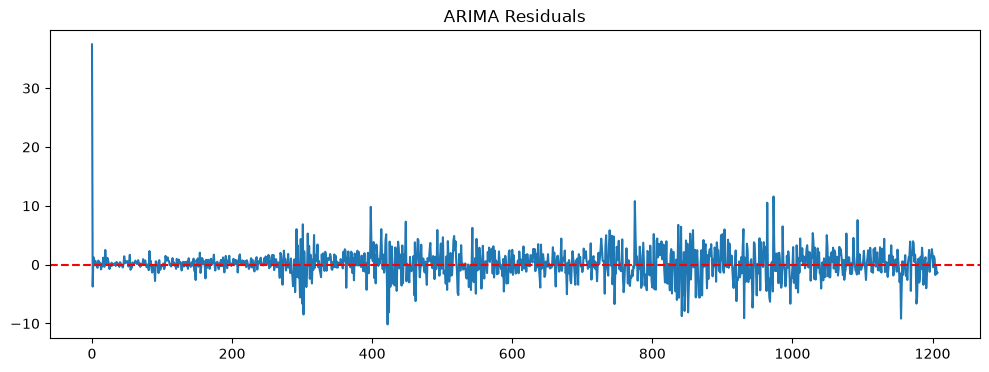

In [16]:
residuals = fitted_model.resid

print(residuals.describe())

residuals.plot(title="ARIMA Residuals", figsize=(12, 4))
plt.axhline(0, color="red", linestyle="--")
plt.show()

In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox

print("First 10 residuals:")
print(residuals.head(10).round(3))

print("\nLjung-Box test:")
print(acorr_ljungbox(residuals, lags=[10, 20], return_df=True))

First 10 residuals:
0    37.437
1    -3.729
2     1.280
3    -0.096
4     0.656
5     0.630
6     0.154
7    -0.334
8    -0.546
9     0.702
dtype: float64

Ljung-Box test:
      lb_stat  lb_pvalue
10  10.144078   0.427945
20  22.258172   0.326667


In [18]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

split_air = int(len(airline) * 0.8)
air_train = airline.iloc[:split_air]
air_test = airline.iloc[split_air:]

sarima_model = SARIMAX(
    air_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
)

sarima_fit = sarima_model.fit(disp=False)

print(sarima_fit.summary())

/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -374.130
Date:                            Tue, 20 Oct 2026   AIC                            758.260
Time:                                    12:33:15   BIC                            771.385
Sample:                                01-01-1949   HQIC                           763.575
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6366      0.334     -1.908      0.056      -1.290       0.017
ma.L1          0.4605      0.372   

In [19]:
sarima_forecast = sarima_fit.forecast(steps=len(air_test))

sarima_mae = mean_absolute_error(air_test, sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(air_test, sarima_forecast))

print("SARIMA MAE:", round(sarima_mae, 2))
print("SARIMA RMSE:", round(sarima_rmse, 2))

SARIMA MAE: 23.56
SARIMA RMSE: 30.14


In [20]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict each month using the same month from the previous year
seasonal_naive = np.tile(
    air_train.iloc[-12:].to_numpy(),
    int(np.ceil(len(air_test) / 12))
)[:len(air_test)]

print("SARIMA MAE:", round(mean_absolute_error(air_test, sarima_forecast), 2))
print("Seasonal Naive MAE:", round(mean_absolute_error(air_test, seasonal_naive), 2))

print("SARIMA RMSE:", round(np.sqrt(mean_squared_error(air_test, sarima_forecast)), 2))
print("Seasonal Naive RMSE:", round(np.sqrt(mean_squared_error(air_test, seasonal_naive)), 2))

SARIMA MAE: 23.56
Seasonal Naive MAE: 64.76
SARIMA RMSE: 30.14
Seasonal Naive RMSE: 75.23


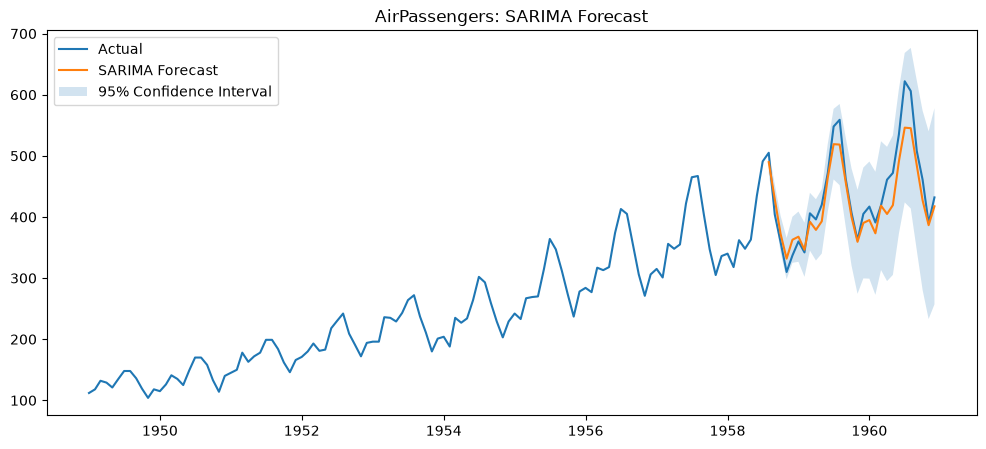

In [21]:
forecast_result = sarima_fit.get_forecast(steps=len(air_test))

forecast_mean = forecast_result.predicted_mean
confidence = forecast_result.conf_int()

plt.figure(figsize=(12, 5))
plt.plot(airline, label="Actual")
plt.plot(forecast_mean.index, forecast_mean, label="SARIMA Forecast")
plt.fill_between(
    forecast_mean.index,
    confidence.iloc[:, 0],
    confidence.iloc[:, 1],
    alpha=0.2,
    label="95% Confidence Interval"
)
plt.legend()
plt.title("AirPassengers: SARIMA Forecast")
plt.show()

In [22]:
walk_train = airline.iloc[:-12]
walk_test = airline.iloc[-12:]

history = list(walk_train)
walk_predictions = []

for actual in walk_test:
    model = SARIMAX(
        history,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(disp=False)
    prediction = float(np.asarray(fitted.forecast(steps=1)).ravel()[0])
    walk_predictions.append(prediction)
    history.append(actual)

walk_predictions = pd.Series(
    walk_predictions,
    index=walk_test.index
)

print("Walk-forward MAE:",
      mean_absolute_error(walk_test, walk_predictions))

print("Walk-forward RMSE:",
      np.sqrt(mean_squared_error(walk_test, walk_predictions)))

Walk-forward MAE: 16.380707822960066
Walk-forward RMSE: 20.840188136806628


In [23]:
# 1 = December, 0 = any other month
air_exog = pd.DataFrame(
    {"is_december": (airline.index.month == 12).astype(int)},
    index=airline.index
)

exog_train = air_exog.iloc[:split_air]
exog_test = air_exog.iloc[split_air:]

print(exog_train.head())
print("\nFuture features shape:", exog_test.shape)

            is_december
Month                  
1949-01-01            0
1949-02-01            0
1949-03-01            0
1949-04-01            0
1949-05-01            0

Future features shape: (29, 1)


In [24]:
exog_model = SARIMAX(
    air_train,
    exog=exog_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

exog_fit = exog_model.fit(disp=False)

exog_forecast = exog_fit.forecast(
    steps=len(air_test),
    exog=exog_test
)

print("Forecast length:", len(exog_forecast))
print("First 5 predictions:")
print(exog_forecast.head())

/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/Users/apple/miniconda3/envs/webscraping/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Forecast length: 29
First 5 predictions:
1958-08-01    491.338984
1958-09-01    429.776735
1958-10-01    371.988814
1958-11-01    331.255534
1958-12-01    361.568724
Freq: MS, Name: predicted_mean, dtype: float64


In [25]:
print("SARIMAX + exog")
print("MAE:", mean_absolute_error(air_test, exog_forecast))
print("RMSE:", np.sqrt(mean_squared_error(air_test, exog_forecast)))

print("\nSARIMA without exog")
print("MAE:", mean_absolute_error(air_test, sarima_forecast))
print("RMSE:", np.sqrt(mean_squared_error(air_test, sarima_forecast)))

print("\nSeasonal-naive baseline")
seasonal_naive = air_train.iloc[-12:].to_numpy()
seasonal_naive = np.tile(
    seasonal_naive,
    int(np.ceil(len(air_test) / 12))
)[:len(air_test)]

print("MAE:", mean_absolute_error(air_test, seasonal_naive))
print("RMSE:", np.sqrt(mean_squared_error(air_test, seasonal_naive)))

SARIMAX + exog
MAE: 25.268045460753616
RMSE: 31.78729726892253

SARIMA without exog
MAE: 23.555686583687383
RMSE: 30.141953155370707

Seasonal-naive baseline
MAE: 64.75862068965517
RMSE: 75.23388818235092


In [26]:
# Get forecasts for the next 12 months
forecast_result = sarima_fit.get_forecast(steps=12)

# Extract the central predictions
forecast_mean = forecast_result.predicted_mean

# Extract the 95% prediction intervals
forecast_intervals = forecast_result.conf_int()

print("Forecast:")
print(forecast_mean)

print("\n95% prediction intervals:")
print(forecast_intervals)

Forecast:
1958-08-01    489.724157
1958-09-01    429.406246
1958-10-01    372.216603
1958-11-01    331.836731
1958-12-01    362.700118
1959-01-01    367.720019
1959-02-01    346.377724
1959-03-01    392.239473
1959-04-01    378.878031
1959-05-01    392.923921
1959-06-01    464.526899
1959-07-01    519.093230
Freq: MS, Name: predicted_mean, dtype: float64

95% prediction intervals:
            lower Passengers  upper Passengers
1958-08-01        471.174269        508.274045
1958-09-01        405.370860        453.441632
1958-10-01        342.565763        401.867442
1958-11-01        298.125599        365.547864
1958-12-01        324.998097        400.402139
1959-01-01        326.627127        408.812911
1959-02-01        302.025888        390.729561
1959-03-01        344.928376        439.550571
1959-04-01        328.736531        429.019532
1959-05-01        340.131089        445.716753
1959-06-01        409.192901        519.860896
1959-07-01        461.339981        576.846479


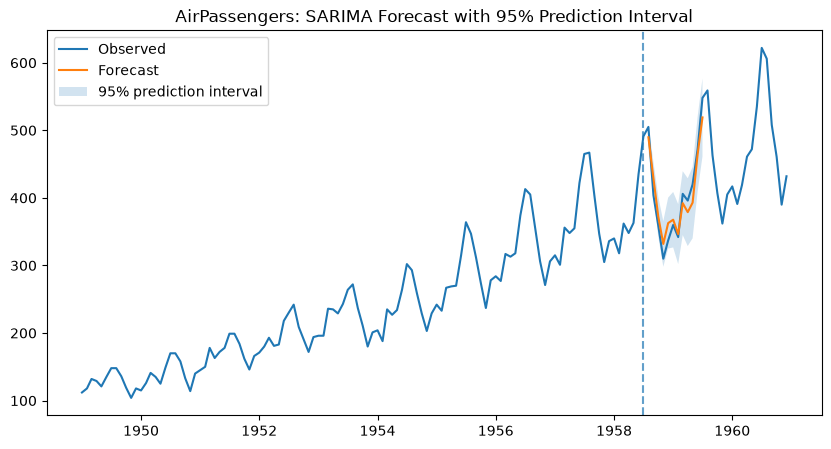

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(airline, label="Observed")
plt.plot(forecast_mean.index, forecast_mean, label="Forecast")

plt.fill_between(
    forecast_intervals.index,
    forecast_intervals.iloc[:, 0].to_numpy(),
    forecast_intervals.iloc[:, 1].to_numpy(),
    alpha=0.2,
    label="95% prediction interval"
)

plt.axvline(air_train.index[-1], linestyle="--", alpha=0.7)
plt.legend()
plt.title("AirPassengers: SARIMA Forecast with 95% Prediction Interval")
plt.show()

In [28]:
!pip install pmdarima

In [29]:
import pmdarima as pm
print(pm.__version__)

2.1.1


In [30]:
auto_model = pm.auto_arima(
    air_train,
    seasonal=True,
    m=12,
    start_p=0,
    start_q=0,
    max_p=3,
    max_q=3,
    start_P=0,
    start_Q=0,
    max_P=2,
    max_Q=2,
    d=None,
    D=1,
    stepwise=True,
    information_criterion="aic",
    trace=True,
    error_action="ignore",
    suppress_warnings=True
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=757.826, Time=0.02 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=755.750, Time=0.06 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=756.380, Time=0.08 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=755.499, Time=0.03 sec
 ARIMA(1,1,0)(0,1,1)[12]             : AIC=755.982, Time=0.08 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=757.649, Time=0.13 sec
 ARIMA(2,1,0)(0,1,0)[12]             : AIC=756.771, Time=0.03 sec
 ARIMA(1,1,1)(0,1,0)[12]             : AIC=756.022, Time=0.04 sec
 ARIMA(0,1,1)(0,1,0)[12]             : AIC=756.011, Time=0.02 sec
 ARIMA(2,1,1)(0,1,0)[12]             : AIC=757.976, Time=0.05 sec
 ARIMA(1,1,0)(0,1,0)[12] intercept   : AIC=757.438, Time=0.05 sec

Best model:  ARIMA(1,1,0)(0,1,0)[12]          
Total fit time: 0.603 seconds
                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observ

In [31]:
auto_forecast = pd.Series(
    auto_model.predict(n_periods=len(air_test)),
    index=air_test.index
)

print("Hand-picked SARIMA")
print("MAE:", mean_absolute_error(air_test, sarima_forecast))
print("RMSE:", np.sqrt(mean_squared_error(air_test, sarima_forecast)))

print("\nauto_arima model")
print("MAE:", mean_absolute_error(air_test, auto_forecast))
print("RMSE:", np.sqrt(mean_squared_error(air_test, auto_forecast)))

Hand-picked SARIMA
MAE: 23.555686583687383
RMSE: 30.141953155370707

auto_arima model
MAE: 28.547408718226208
RMSE: 35.08281301131711


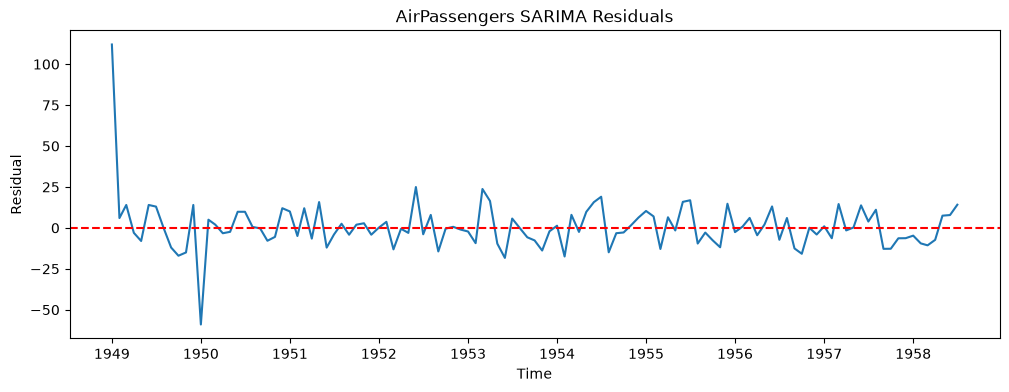

In [32]:
residuals = sarima_fit.resid

plt.figure(figsize=(12, 4))
plt.plot(residuals)
plt.axhline(0, color="red", linestyle="--")
plt.title("AirPassengers SARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.show()

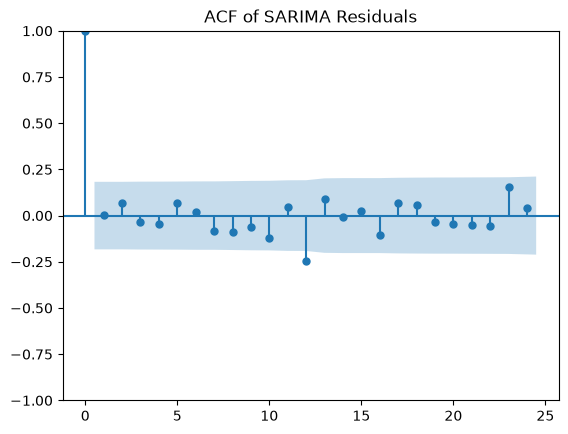

In [33]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(residuals, lags=24)
plt.title("ACF of SARIMA Residuals")
plt.show()

In [34]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ljung_box = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    return_df=True
)

print(ljung_box)

      lb_stat  lb_pvalue
12  13.848341   0.310498
24  22.610733   0.542863
